# Housing Permits-to-Alpha — Building Materials
## Research-grade fixed-vintage pilot (19 October 2026)
**Verdict:** the housing-activity features do not beat a historical-mean six-month industrial-output forecast. **No equity alpha established.**


> **Notebook verification caveat.** The original frozen-snapshot results cited here are included in the repository; newly added charts and diagnostics are code, not archived outputs until the notebook is re-executed. This tests an **economic-output lead relationship**, not stock returns.


## 1. Hypotheses and economic mechanism
Housing permits/starts may lead demand for cement, glass, and other nonmetallic mineral products. H1: incremental predictability of forward industrial output. H2: effect survives baseline and shifted-signal placebos. H3 (future): security-level abnormal returns; **not tested**.


In [1]:
import json, pandas as pd, matplotlib.pyplot as plt
from housing_alpha import read_snapshot, make_panel, walk_forward, evaluate, summarize_forecasts
raw=read_snapshot('fred_housing_materials_snapshot_2010_2026.csv')
summary,oos=evaluate(raw)
print(json.dumps(summary['main'],indent=2))


{
  "mean": {
    "rmse_pp": 4.807942146935425,
    "mae_pp": 3.4700941088693793,
    "direction_accuracy": 0.5
  },
  "ar": {
    "rmse_pp": 4.869030125601899,
    "mae_pp": 3.5638408524571425,
    "direction_accuracy": 0.42857142857142855
  },
  "macro": {
    "rmse_pp": 4.873730965978551,
    "mae_pp": 3.424629502108887,
    "direction_accuracy": 0.6326530612244898
  },
  "housing": {
    "rmse_pp": 5.109383912750889,
    "mae_pp": 3.619693998436041,
    "direction_accuracy": 0.5918367346938775
  },
  "gap": {
    "rmse_pp": 4.875133964994336,
    "mae_pp": 3.4231381673454564,
    "direction_accuracy": 0.6224489795918368
  }
}


### 1A. Hypothesis matrix and countertheses
**H1:** permitting starts a construction spending pipeline, potentially leading cement/glass/ceramic manufacturing. **H2:** permits and starts add **out-of-sample** signal over historical mean, industry autoregression and manufacturing/rate controls. **H3:** any gain generalizes across a three-month horizon, post-COVID regimes and wood products, not just six-month mineral output. **H4 (future, not tested):** filing-known building-product revenue exposure predicts earnings changes and sector-neutral stock returns. Countertheses: import substitution, large public works projects, housing affordability/rates and decoupling of building activity from domestic materials output.


In [2]:
sources=pd.read_csv('source_register.csv')
display(sources)
print('Rows and dates:',len(raw),raw.index.min().date(),raw.index.max().date())
assert raw.index.is_unique and raw.notna().all().all()


,series,description,source_agency,source_url,grade,frequency,units,first_observation_in_snapshot,last_observation_in_snapshot,latest_fred_update_observed_as_of_2026_10_19,release_and_point_in_time_caveat
0,PERMIT,Total privately-owned housing units authorized,U.S. Census Bureau and HUD,https://fred.stlouisfed.org/series/PERMIT,A,monthly,thousand units SAAR,2010-01,2026-08,2026-09-24,Aug-2026 observation updated after initial Sep...
1,HOUST,Total privately-owned housing units started,U.S. Census Bureau and HUD,https://fred.stlouisfed.org/series/HOUST,A,monthly,thousand units SAAR,2010-01,2026-08,2026-09-17,Preliminary/revised historical readings; actua...
2,IPG327S,Nonmetallic mineral products industrial produc...,Federal Reserve Board G17,https://fred.stlouisfed.org/series/IPG327S,A,monthly,index 2017=100 SA,2010-01,2026-08,2026-10-16,September 2026 exists but excluded for common ...
3,IPG321S,Wood products industrial production NAICS 321,Federal Reserve Board G17,https://fred.stlouisfed.org/series/IPG321S,A,monthly,index 2017=100 SA,2010-01,2026-08,2026-10-16,Wood industry robustness target; revisions unr...
4,IPMAN,Total manufacturing industrial production,Federal Reserve Board G17,https://fred.stlouisfed.org/series/IPMAN,A,monthly,index 2017=100 SA,2010-01,2026-08,2026-10-16,Aggregate macro control; revisions unresolved
5,FEDFUNDS,Effective federal funds rate,Federal Reserve Board H15,https://fred.stlouisfed.org/series/FEDFUNDS,A,monthly,percent NSA,2010-01,2026-08,2026-10-01,Monthly average of daily figures; two-month co...


Rows and dates: 200 2010-01-01 2026-08-01


### 1B. Frozen source definitions
The Census/HUD **PERMIT** and **HOUST** series are building permits/starts (thousands SAAR). Federal Reserve **IPG327S** and **IPG321S** represent mineral and wood-product manufacturing IP; **IPMAN** is total manufacturing output; **FEDFUNDS** controls for the interest-rate regime. Check exact FRED source links, observational range, grade and publication caveats in `source_register.csv`. Data are official *revised* observations, not a contemporaneous-vintage trading tape.


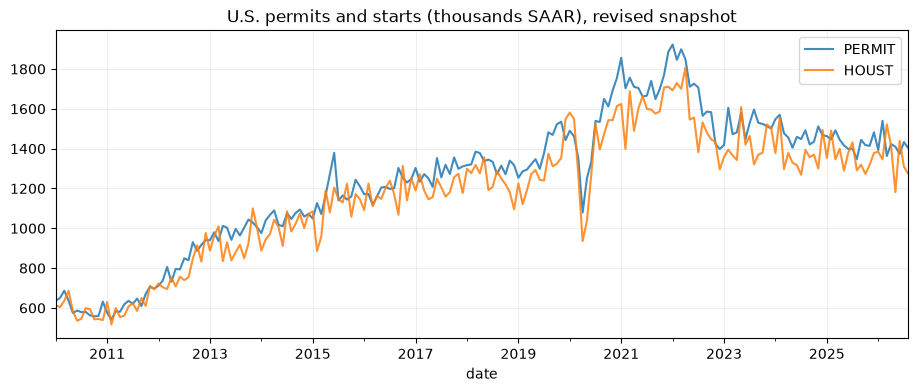

In [3]:
fig,ax=plt.subplots(figsize=(11,4))
raw[['PERMIT','HOUST']].plot(ax=ax,alpha=.85)
ax.set_title('U.S. permits and starts (thousands SAAR), revised snapshot');ax.grid(alpha=.2);plt.show()


### 1C. Demand transmission and lag choice
A new permit is not the same as an approved, funded project. Housing starts and shipments can lead or lag plant utilization differently, and the NAICS 327 index also reflects public infrastructure, industrial construction and nonresidential demand. Two months of feature delay reduce *calendar* leakage but do not repair the historical revisions of rates, census series or production.


,permits_lag,starts_lag,housing_gap,actual
count,180.000,180.000,180.000,180.000
mean,5.764,5.610,0.154,0.681
std,12.660,14.309,9.673,3.875
min,-30.464,-30.673,-28.483,-18.378
25%,-1.147,-3.150,-6.254,-1.067
50%,5.812,4.357,-0.008,0.868
75%,11.383,13.785,7.304,2.814
max,46.046,46.424,26.647,16.892


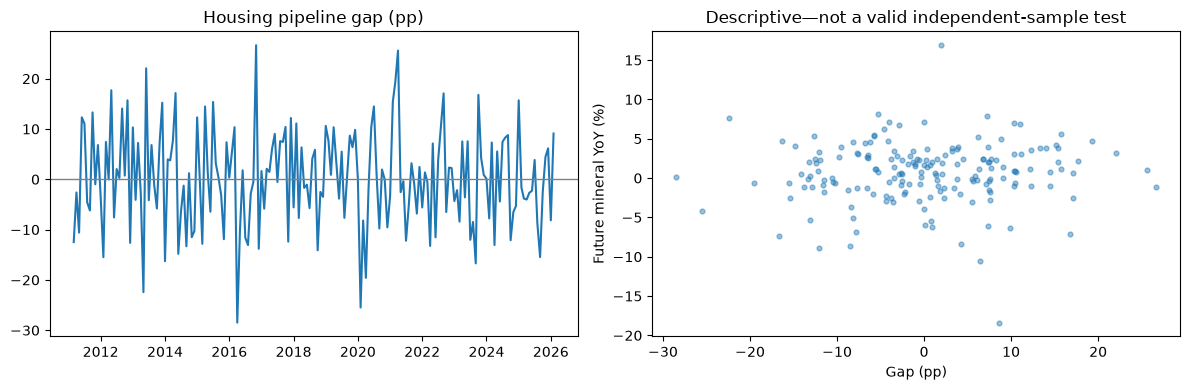

In [4]:
p=make_panel(raw)
display(p[['permits_lag','starts_lag','housing_gap','actual']].describe().round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(p.index,p['housing_gap']);axes[0].axhline(0,color='gray',lw=1);axes[0].set_title('Housing pipeline gap (pp)')
axes[1].scatter(p['housing_gap'],p['actual'],s=12,alpha=.45);axes[1].set_xlabel('Gap (pp)');axes[1].set_ylabel('Future mineral YoY (%)');axes[1].set_title('Descriptive—not a valid independent-sample test')
plt.tight_layout();plt.show()


## 2. Fixed features and leakage audit
Formation t uses t−2 log YoY permits, starts, sector production and total manufacturing, plus the t−2 effective funds rate. Outcome is t+6 sector-production YoY. At t, only training origins ≤t−8 are eligible; the dataset is revised ex post, not genuine PIT.


In [5]:
display(pd.DataFrame(summary['main']).T.round(4))
display(oos[['actual','mean','macro','housing']].tail(10).round(2))


,rmse_pp,mae_pp,direction_accuracy
mean,4.8079,3.4701,0.5000
ar,4.8690,3.5638,0.4286
macro,4.8737,3.4246,0.6327
housing,5.1094,3.6197,0.5918
gap,4.8751,3.4231,0.6224


,actual,mean,macro,housing
formation,,,,
2025-05-01,-0.91,0.47,-3.39,-3.28
2025-06-01,-2.00,0.49,-3.09,-3.02
2025-07-01,-0.17,0.50,-2.98,-2.89
2025-08-01,-1.48,0.50,-2.65,-2.65
2025-09-01,-2.48,0.51,-2.41,-2.42
2025-10-01,-0.39,0.52,-2.49,-2.73
2025-11-01,2.42,0.53,-2.13,-2.09
2025-12-01,5.26,0.53,-1.76,-1.82
2026-01-01,4.54,0.52,-1.54,-1.70


### 2A. Mathematical formulation
For any positive monthly series \(X_t\), \(G_t(X)=100\ln(X_t/X_{t-12})\). At origin \(t\), use \(p_t=G_{t-2}(PERMIT)\), \(s_t=G_{t-2}(HOUST)\), and \(f_t=p_t-s_t\). The target is \(Y_t=G_{t+6}(IPG327S)\), a **future YoY level growth**, *not* the growth from t to t+6, and emphatically not a stock return.
Fit Ridge with fixed \(\alpha=25\) after train-only standardization. Only train origins \(u\le t-8\) can be used. The historical-mean benchmark forecasts the matured training target mean.


In [6]:
display(pd.DataFrame(summary['main']).T.rename_axis('model').sort_values('rmse_pp').round(4))
print('OOS n',len(oos),'first',oos.index.min().date(),'last',oos.index.max().date())
assert len(oos)==summary['oos']['n']


,rmse_pp,mae_pp,direction_accuracy
model,,,
mean,4.8079,3.4701,0.5000
ar,4.8690,3.5638,0.4286
macro,4.8737,3.4246,0.6327
gap,4.8751,3.4231,0.6224
housing,5.1094,3.6197,0.5918


OOS n 98 first 2018-01-01 last 2026-02-01


### 2B. Full primary outcome
The repository's fixed-snapshot evaluation reports **98** expanding-window origins. RMSE: mean **4.8079 pp**; AR **4.8690**; macro controls **4.8737**; macro + housing **5.1094**; macro + gap **4.8751**. Hence adding separate permits/starts **hurts RMSE** versus both the historical mean and macro controls. Sign accuracy alone does not rescue poor magnitude calibration.


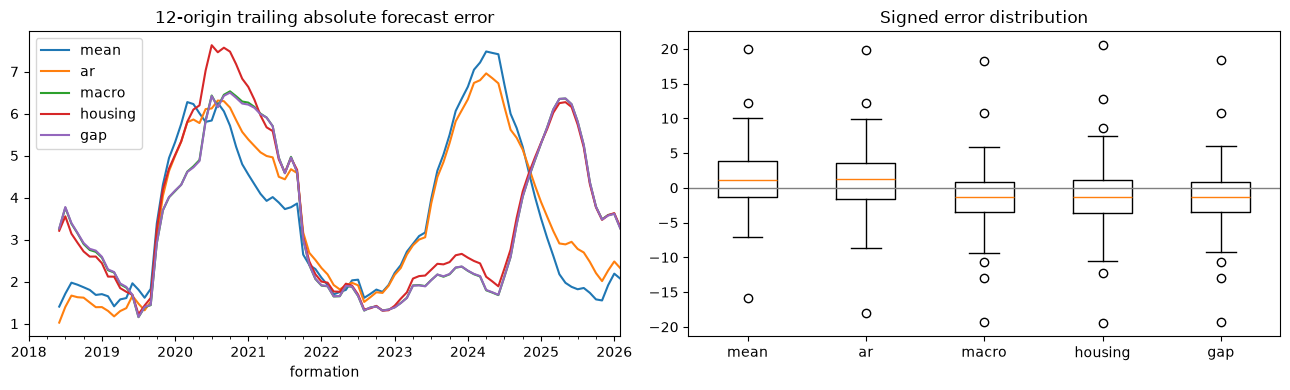

In [7]:
loss=oos[['mean','ar','macro','housing','gap']].sub(oos['actual'],axis=0)
fig,axes=plt.subplots(1,2,figsize=(13,4))
loss.abs().rolling(12,min_periods=6).mean().plot(ax=axes[0]);axes[0].set_title('12-origin trailing absolute forecast error')
axes[1].boxplot([loss[c] for c in loss.columns],tick_labels=list(loss.columns));axes[1].axhline(0,color='gray',lw=1);axes[1].set_title('Signed error distribution')
plt.tight_layout();plt.show()


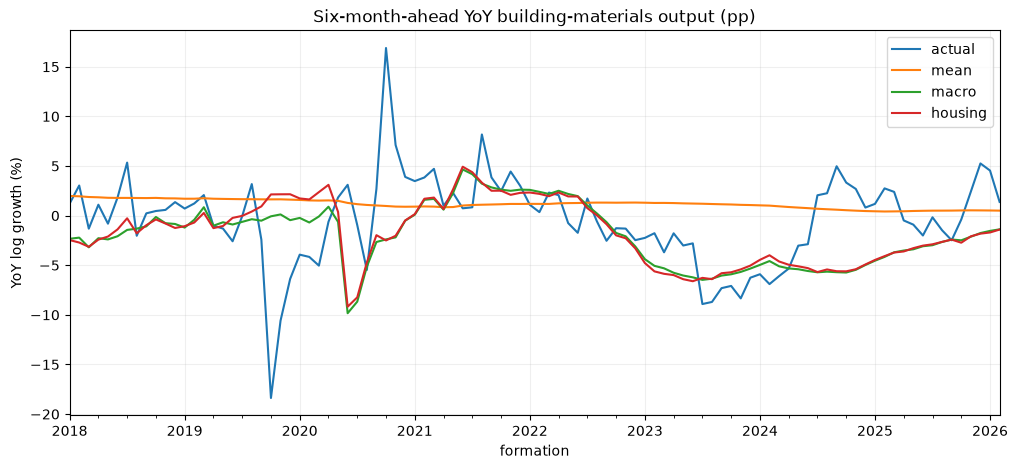

In [8]:
ax=oos[['actual','mean','macro','housing']].plot(figsize=(12,5),title='Six-month-ahead YoY building-materials output (pp)')
ax.set_ylabel('YoY log growth (%)'); ax.grid(alpha=.2); plt.show()


### 2C. Paired loss is more informative than a headline RMSE
The comparison uses **identical test origins**: \(d_t=(Y_t-\hat Y^{macro}_t)^2-(Y_t-\hat Y^{housing}_t)^2\). A negative mean implies an inferior housing model. Since target outcomes overlap in calendar time, independent t-tests exaggerate precision; preregistered block-resampling or nonoverlapping origins are required for formal claims.


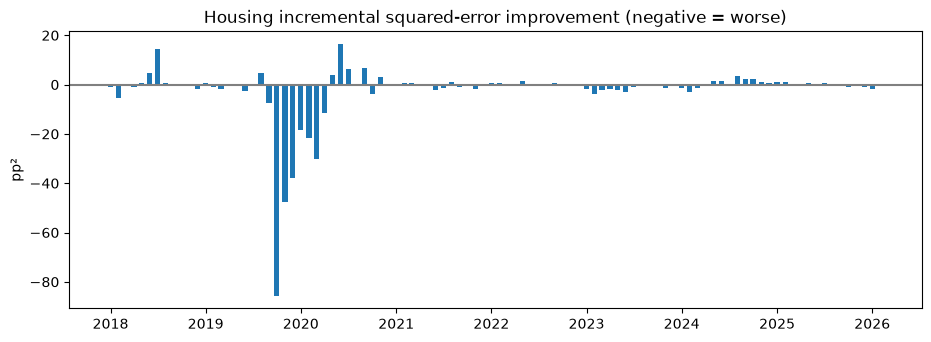

mean gain in squared error: -2.352550439139373


In [9]:
gain=(oos.actual-oos.macro)**2-(oos.actual-oos.housing)**2
fig,ax=plt.subplots(figsize=(11,3.6));ax.bar(oos.index,gain,width=20);ax.axhline(0,color='gray');ax.set_title('Housing incremental squared-error improvement (negative = worse)');ax.set_ylabel('pp²');plt.show()
print('mean gain in squared error:',float(gain.mean()))


### 2D. Feature redundancy question
Starts and permits correlate mechanically with interest rates and industry activity. In a small time-series sample, adding two noisy proxy variables can worsen forecasts despite a plausible economic mechanism. The compact gap variant barely changes performance relative to macro controls, suggesting the primary story is not an independent short-horizon predictive edge.


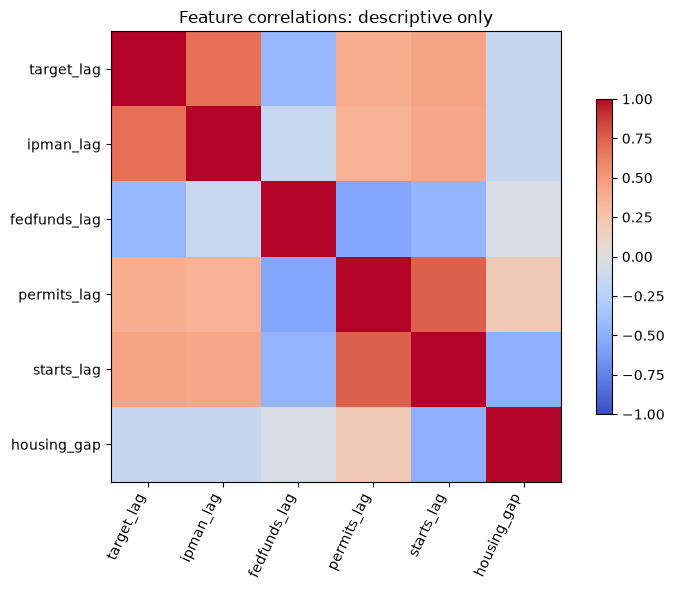

In [10]:
corr=p[['target_lag','ipman_lag','fedfunds_lag','permits_lag','starts_lag','housing_gap']].corr()
fig,ax=plt.subplots(figsize=(8,6));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(range(len(corr)),corr.columns,rotation=65,ha='right');ax.set_yticks(range(len(corr)),corr.index);fig.colorbar(im,ax=ax,shrink=.7);ax.set_title('Feature correlations: descriptive only');plt.tight_layout();plt.show()


## 3. Placebo, ablation and regimes
Compare historical mean, target autoregression, manufacturing/rate controls, full housing features and permits-minus-starts gap. Re-run 3-month horizon, wood-product control and lag-only 12/24/36-month placebo. Placebos have unequal eligible samples and do not yield a formal p-value.


In [11]:
print('Three-month horizon:',json.dumps(summary['three_month_horizon']['metrics'],indent=2))
print('Wood industry:',json.dumps(summary['wood_product_negative_control']['metrics'],indent=2))
print('Lag-only placebos:',json.dumps(summary['lag_only_placebos'],indent=2))
print('Regime sensitivity:',json.dumps(summary['regime_sensitivity'],indent=2))


Three-month horizon: {
  "mean": {
    "rmse_pp": 4.709641687539857,
    "mae_pp": 3.3719631610359486,
    "direction_accuracy": 0.5148514851485149
  },
  "ar": {
    "rmse_pp": 4.304918632692282,
    "mae_pp": 3.1302914723699056,
    "direction_accuracy": 0.5544554455445545
  },
  "macro": {
    "rmse_pp": 4.293015809715738,
    "mae_pp": 3.1055110116087694,
    "direction_accuracy": 0.6435643564356436
  },
  "housing": {
    "rmse_pp": 4.462659845408249,
    "mae_pp": 3.2380499712443296,
    "direction_accuracy": 0.5841584158415841
  },
  "gap": {
    "rmse_pp": 4.309914531908806,
    "mae_pp": 3.1372441513145803,
    "direction_accuracy": 0.6435643564356436
  }
}
Wood industry: {
  "mean": {
    "rmse_pp": 5.393180117828309,
    "mae_pp": 4.23743884653039,
    "direction_accuracy": 0.45918367346938777
  },
  "ar": {
    "rmse_pp": 5.202469039235269,
    "mae_pp": 4.108601902998136,
    "direction_accuracy": 0.47959183673469385
  },
  "macro": {
    "rmse_pp": 5.819377215697258,
    

### 3A. Robustness summary from the frozen analysis
For a **3-month** target, the housing model loses to macro controls (RMSE **4.4627 vs 4.2930** pp); for the wood-products comparison it loses to the historical mean (**5.6401 vs 5.3932** pp). Excluding early COVID dates and focusing on post-2022 also fails to deliver an obvious incremental advantage. These are falsification exercises, not ex post model-shopping opportunities.


In [12]:
rows=[]
for name,item in [('3-month',summary['three_month_horizon']),('wood',summary['wood_product_negative_control'])]:
 for model,metrics in item['metrics'].items(): rows.append({'experiment':name,'model':model,'rmse':metrics['rmse_pp']})
display(pd.DataFrame(rows).pivot(index='model',columns='experiment',values='rmse').round(3))


experiment,3-month,wood
model,,
ar,4.305,5.202
gap,4.310,5.821
housing,4.463,5.640
macro,4.293,5.819
mean,4.710,5.393


### 3B. Placebo timing cannot be conflated with a null distribution
The 12-, 24-, and 36-month lag-only placebos use older housing features without future leakage; the data interval changes when earlier lags are introduced. No meaningful randomization p-value results. The appropriate future test would define a consistent test sample and a block-aware empirical null before examining returns.


,n,housing_rmse_pp
12,98,4.926
24,98,5.124
36,98,5.005


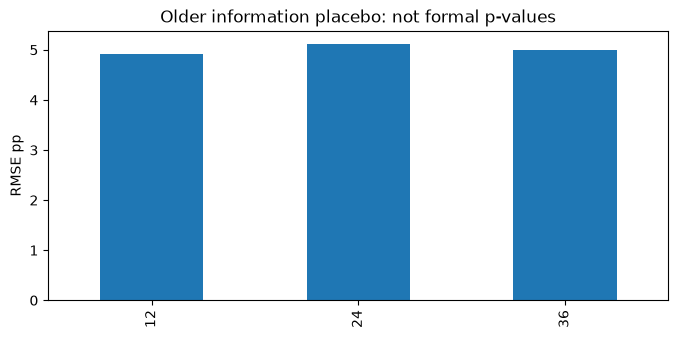

In [13]:
lags=pd.DataFrame(summary['lag_only_placebos']).T
lags['n']=lags['n'].astype(int);lags['housing_rmse_pp']=lags['housing_rmse_pp'].astype(float)
display(lags[['n','housing_rmse_pp']].round(3))
ax=lags['housing_rmse_pp'].plot.bar(title='Older information placebo: not formal p-values',figsize=(8,3.5));ax.set_ylabel('RMSE pp');plt.show()


### 3C. Explicit regime instability
A secular housing shortage does not erase mortgage-rate cycles or project cancellations. Display the sample shift under post-2022 and COVID exclusions. Regime splits further reduce independent evidence, so a seemingly better number from one slice must not be cherry-picked.


In [14]:
reg=[]
for name,item in summary['regime_sensitivity'].items():
 for k,v in item['metrics'].items(): reg.append({'regime':name,'n':item['n'],'model':k,'rmse_pp':v['rmse_pp']})
display(pd.DataFrame(reg).pivot(index='model',columns='regime',values='rmse_pp').round(3))


regime,excluding_covid_2020_03_to_2021_12,post_2022
model,,
ar,4.680,4.341
gap,4.417,4.031
housing,4.725,4.059
macro,4.412,4.032
mean,4.810,4.408


## 4. Bias audit and future tests
The FRED snapshot contains revised observations; a fixed two-month release lag does not remove revision look-ahead. Overlapping six-month labels invalidate independent-sample significance tests. No company exposure, stock return, dividends, transaction costs, or delistings are included. Rebuild with ALFRED vintages and a preregistered 2027+ holdout before claiming alpha.


In [15]:
print('\n'.join('- '+warning for warning in summary['warnings']))


- All historic FRED values are latest/revised snapshot, not ALFRED point-in-time vintages.
- Two-month lag is a conservative approximation, not a verified release calendar.
- Six-month overlapping targets imply strongly dependent forecast errors.
- This is an industrial-production nowcast/forecast test, not a securities-return test.
- Housing activity is cyclical and nonmetallic mineral output has nonhousing uses.
- Fixed hyperparameters are researcher choices, not a pre-registered 2018 design.
- Lag-only placebos are diagnostics, not formal randomization inference.


### 4A. Auditable bias register
| Risk | Status | Remediation |
|---|---|---|
| Release calendars | t−2 lag assumption | archived Census/G.17 release dates |
| Historical revisions | **FAIL**: FRED snapshot latest/revised | ALFRED vintages |
| Overlap | 6-month forward YoY targets | nonoverlap and HAC/block CI |
| Industry choice | selected after concept formation | preregistered peer-sector universe |
| Target leakage | train cut at t−8 | verify vintages |
| Equity mapping | no company-level historical exposure | dated SEC 10-K line-item mix |
| Tradability | production index only | adjusted stock total returns + delistings |
| Costs | none tested | spreads, fees, turnover, capacity |


### 4B. Follow-on: from industry economics to investable alpha
Collect frozen vintages of permits, starts, county-level construction, cement shipment data and rates. Map building-product producers using filings **available at the formation date** to specific residential categories; estimate quarterly earnings-surprise lead and sector-neutral return rank IC. Test over market/value/momentum exposures, across regional and macro regimes, and finally a fully adjusted, cost-aware long–short P&L. **Until that exists, label this only a macro-output factor falsification.**


## 5. Final conclusion & reproducibility
**Rejected H2:** the housing proxy worsens OOS RMSE versus simpler controls; the proposed alpha is not validated. This amended notebook is a **richer reproducible research narrative**, but the additional code outputs still require notebook run-all verification. From this folder: `pip install -r requirements.txt`, `python -m pytest -q test_housing_alpha.py`, `jupyter nbconvert --execute --to notebook housing_permits_alpha_research.ipynb --output executed.ipynb`. Preserve the frozen observation-vintage caveat.
